# Energy and TPOT vs batch size: laptop vs T4

Loads both v2 sweep CSVs, averages each configuration over its three repeats, and plots
energy per token and TPOT against batch size, one line per model. Laptop on the left, T4 on the right.
One row per prompt length, since prompt length shifts both targets.

- Batch axis is log 2, since batch sizes double (1 to 128).
- The y axis is also log: energy spans 6 to 1600 mJ/token across models, so a linear axis would flatten the small models.
- Each row shares one y range across both GPUs so the two panels can be compared directly.
- Only `ok` rows are averaged. The laptop's one out-of-memory config (TinyLlama, batch 128, prompt 512) has no point, so that line stops at batch 64.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter, NullLocator

# Works whether the notebook runs from notebooks/ or from the repo root.
DATA = Path("../data") if Path("../data").exists() else Path("data")

GPUS = {
    "RTX 5070 Ti laptop": DATA / "sweep_v2_nvidia_geforce_rtx_5070_ti_laptop_gpu.csv",
    "Tesla T4": DATA / "sweep_v2_tesla_t4.csv",
}
frames = []
for label, path in GPUS.items():
    df = pd.read_csv(path)
    df["gpu"] = label
    frames.append(df)
runs = pd.concat(frames, ignore_index=True)
print(runs.groupby(["gpu", "status"]).size().unstack(fill_value=0))

status               ok  oom  oom_skipped
gpu                                      
RTX 5070 Ti laptop  357    1            2
Tesla T4            360    0            0


In [2]:
# Mean over the three repeats of each (GPU, model, prompt length, batch size). OOM rows are dropped.
ok = runs[runs["status"] == "ok"]
avg = (ok.groupby(["gpu", "model", "params", "prompt_len", "batch_size"], as_index=False)
         .agg(energy_mj=("energy_per_token_j", lambda s: s.mean() * 1000),
              tpot_ms=("tpot_s", lambda s: s.mean() * 1000),
              repeats=("repeat", "size")))
assert (avg["repeats"] == 3).all(), "every plotted point should be the mean of exactly 3 repeats"
avg.head()

,gpu,model,params,prompt_len,batch_size,energy_mj,tpot_ms,repeats
0,RTX 5070 Ti laptop,Qwen/Qwen2.5-0.5B,494032768,128,1,1361.692708,22.918599,3
1,RTX 5070 Ti laptop,Qwen/Qwen2.5-0.5B,494032768,128,2,694.593099,23.768011,3
2,RTX 5070 Ti laptop,Qwen/Qwen2.5-0.5B,494032768,128,4,328.930664,20.858353,3
3,RTX 5070 Ti laptop,Qwen/Qwen2.5-0.5B,494032768,128,8,181.011556,21.945119,3
4,RTX 5070 Ti laptop,Qwen/Qwen2.5-0.5B,494032768,128,16,102.920003,22.692093,3


In [3]:
# Fixed model order (smallest to largest) and a fixed colour + marker per model, identical in every
# panel. Markers differ too, so models can be told apart without relying on colour.
MODELS = (avg[["model", "params"]].drop_duplicates().sort_values("params")["model"].tolist())
SHORT = {"distilbert/distilgpt2": "distilGPT-2 (82M)", "openai-community/gpt2": "GPT-2 (124M)",
         "openai-community/gpt2-medium": "GPT-2 medium (355M)", "Qwen/Qwen2.5-0.5B": "Qwen2.5-0.5B (494M)",
         "TinyLlama/TinyLlama_v1.1": "TinyLlama-1.1B (1.1B)"}
COLORS = ["#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac"]   # validated colourblind-safe order
MARKERS = ["o", "s", "^", "D", "v"]
STYLE = {m: dict(color=c, marker=k) for m, c, k in zip(MODELS, COLORS, MARKERS)}
BATCHES = sorted(avg["batch_size"].unique())
PROMPTS = sorted(avg["prompt_len"].unique())

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9c9c9c", "axes.labelcolor": "#333333",
                     "xtick.color": "#555555", "ytick.color": "#555555"})


def plot_vs_batch(column, ylabel, title):
    gpus = list(GPUS)
    fig, axes = plt.subplots(len(PROMPTS), len(gpus), figsize=(11, 3.3 * len(PROMPTS)),
                             sharex=True, sharey="row", constrained_layout=True)
    for r, prompt in enumerate(PROMPTS):
        for c, gpu in enumerate(gpus):
            ax = axes[r, c]
            for model in MODELS:
                d = avg[(avg.gpu == gpu) & (avg.model == model) & (avg.prompt_len == prompt)]
                d = d.sort_values("batch_size")
                ax.plot(d["batch_size"], d[column], label=SHORT.get(model, model), linewidth=2,
                        markersize=6, markeredgecolor="white", markeredgewidth=1, **STYLE[model])
            ax.set_xscale("log", base=2)
            ax.set_yscale("log")
            ax.xaxis.set_major_locator(FixedLocator(BATCHES))
            ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x)}"))
            ax.xaxis.set_minor_locator(NullLocator())
            ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))   # labels at 1-2-5 steps
            ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
            ax.yaxis.set_minor_formatter(NullFormatter())
            ax.grid(True, which="major", color="#e6e6e6", linewidth=0.8)
            ax.grid(True, which="minor", axis="y", color="#f2f2f2", linewidth=0.5)
            ax.set_axisbelow(True)
            if r == 0:
                ax.set_title(gpu, fontsize=11, fontweight="bold", color="#222222")
            if c == 0:
                ax.set_ylabel(f"prompt {prompt}\n{ylabel}")
            if r == len(PROMPTS) - 1:
                ax.set_xlabel("batch size (log scale)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=len(MODELS), frameon=False)
    fig.suptitle(title, fontsize=13, color="#222222")
    plt.show()
    return fig

## Energy per token vs batch size

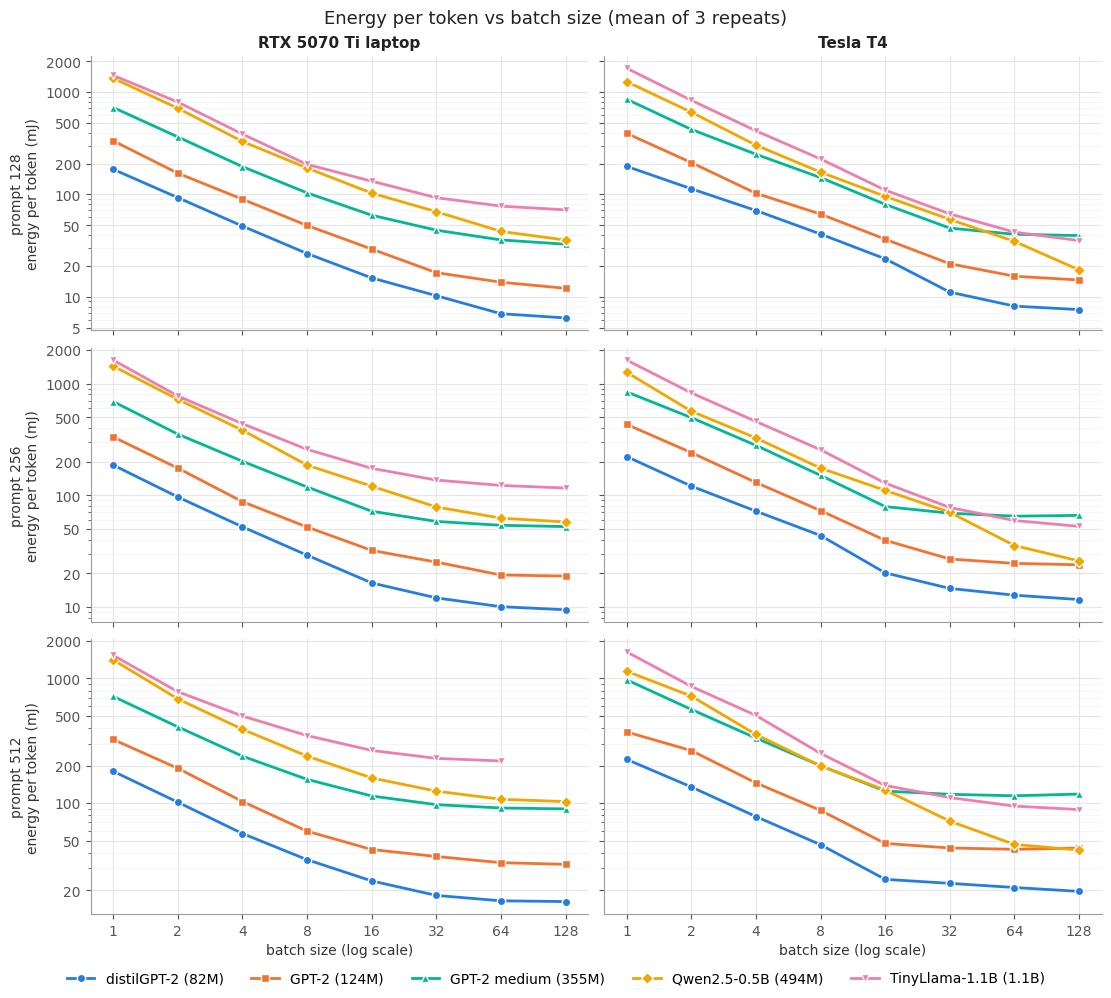

In [4]:
fig_energy = plot_vs_batch("energy_mj", "energy per token (mJ)",
                           "Energy per token vs batch size (mean of 3 repeats)")

## TPOT vs batch size

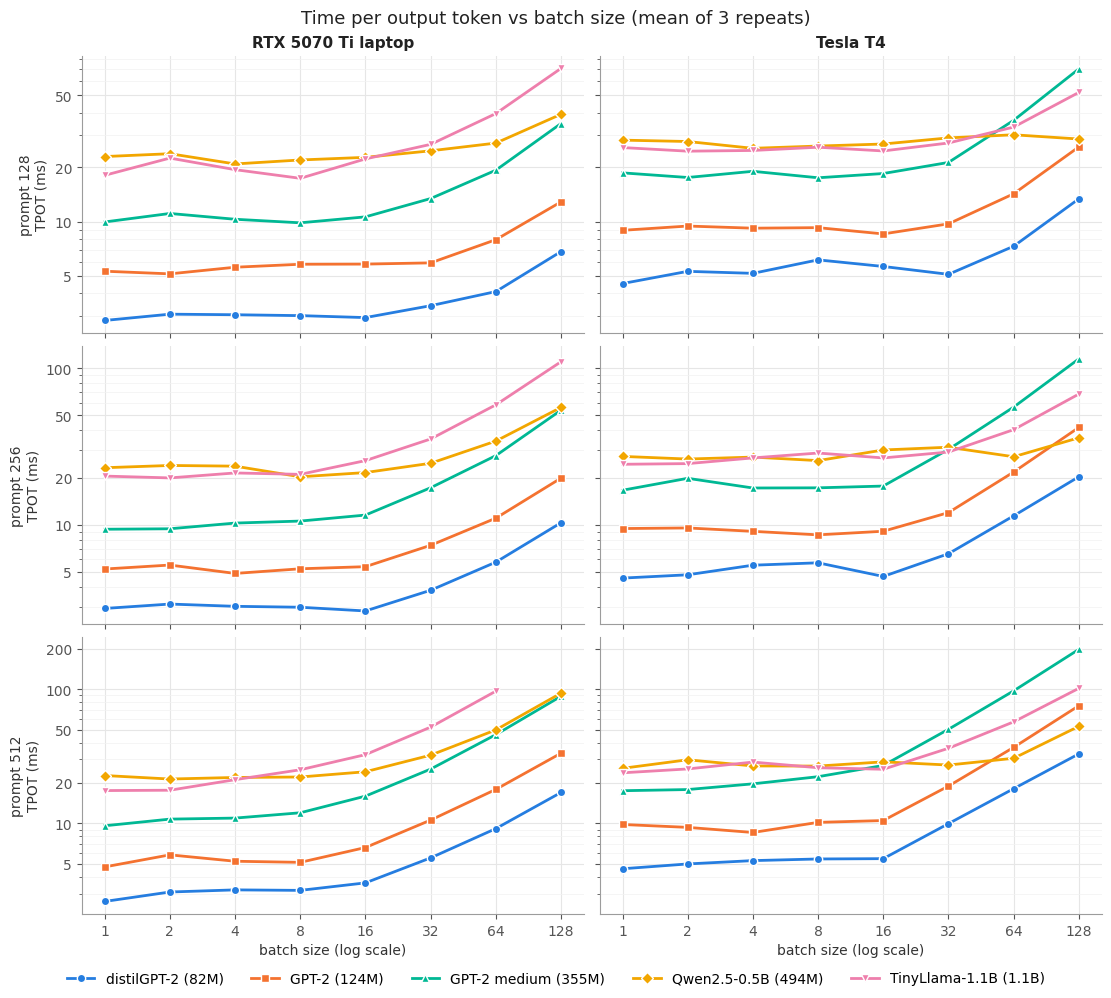

In [5]:
fig_tpot = plot_vs_batch("tpot_ms", "TPOT (ms)", "Time per output token vs batch size (mean of 3 repeats)")

## The numbers behind the plots

The same averages as tables, one per target, so values can be read exactly.

In [6]:
# Models listed smallest to largest, same order as the legend.
table = avg.assign(model=pd.Categorical(avg["model"].map(SHORT), [SHORT[m] for m in MODELS], ordered=True))
for column, name in [("energy_mj", "Energy per token (mJ)"), ("tpot_ms", "TPOT (ms)")]:
    print(name)
    display(table.pivot_table(index=["gpu", "prompt_len", "model"], columns="batch_size",
                              values=column, observed=True).round(1))

Energy per token (mJ)


batch_size                                              1      2      4    \
gpu                prompt_len model                                         
RTX 5070 Ti laptop 128        distilGPT-2 (82M)       175.8   93.0   49.0   
                              GPT-2 (124M)            333.5  161.0   89.7   
                              GPT-2 medium (355M)     706.0  364.4  186.6   
                              Qwen2.5-0.5B (494M)    1361.7  694.6  328.9   
                              TinyLlama-1.1B (1.1B)  1455.8  797.5  388.1   
                   256        distilGPT-2 (82M)       186.1   96.3   52.0   
                              GPT-2 (124M)            332.3  174.7   87.4   
                              GPT-2 medium (355M)     689.9  351.9  201.2   
                              Qwen2.5-0.5B (494M)    1431.8  720.7  382.0   
                              TinyLlama-1.1B (1.1B)  1622.8  774.0  436.7   
                   512        distilGPT-2 (82M)       179.9  101.6   57.0   
                              GPT-2 (124M)            323.8  190.1  103.0   
                              GPT-2 medium (355M)     717.5  408.9  237.9   
                              Qwen2.5-0.5B (494M)    1409.8  685.6  391.0   
                              TinyLlama-1.1B (1.1B)  1533.5  782.5  499.7   
Tesla T4           128        distilGPT-2 (82M)       187.9  113.5   69.6   
                              GPT-2 (124M)            394.7  204.6  102.6   
                              GPT-2 medium (355M)     850.3  431.4  246.8   
                              Qwen2.5-0.5B (494M)    1262.4  635.5  302.7   
                              TinyLlama-1.1B (1.1B)  1706.8  830.6  418.1   
                   256        distilGPT-2 (82M)       221.8  120.6   71.9   
                              GPT-2 (124M)            430.9  240.6  130.0   
                              GPT-2 medium (355M)     842.2  494.9  279.3   
                              Qwen2.5-0.5B (494M)    1261.8  565.2  325.4   
                              TinyLlama-1.1B (1.1B)  1622.8  825.1  457.5   
                   512        distilGPT-2 (82M)       224.2  134.8   78.0   
                              GPT-2 (124M)            372.3  263.9  145.3   
                              GPT-2 medium (355M)     975.2  564.4  332.6   
                              Qwen2.5-0.5B (494M)    1142.4  721.9  355.2   
                              TinyLlama-1.1B (1.1B)  1633.8  863.5  505.3   

batch_size                                             8      16     32   \
gpu                prompt_len model                                        
RTX 5070 Ti laptop 128        distilGPT-2 (82M)       26.5   15.3   10.3   
                              GPT-2 (124M)            49.7   29.3   17.2   
                              GPT-2 medium (355M)    103.5   62.6   44.7   
                              Qwen2.5-0.5B (494M)    181.0  102.9   67.8   
                              TinyLlama-1.1B (1.1B)  196.5  134.7   92.9   
                   256        distilGPT-2 (82M)       29.0   16.4   12.0   
                              GPT-2 (124M)            51.9   32.0   25.1   
                              GPT-2 medium (355M)    118.4   71.8   58.2   
                              Qwen2.5-0.5B (494M)    185.8  120.3   78.4   
                              TinyLlama-1.1B (1.1B)  257.3  174.0  136.6   
                   512        distilGPT-2 (82M)       35.2   23.7   18.2   
                              GPT-2 (124M)            59.5   42.4   37.3   
                              GPT-2 medium (355M)    155.0  114.0   97.1   
                              Qwen2.5-0.5B (494M)    238.3  159.3  124.7   
                              TinyLlama-1.1B (1.1B)  348.2  264.5  228.6   
Tesla T4           128        distilGPT-2 (82M)       41.0   23.5   11.1   
                              GPT-2 (124M)            64.2   36.6   21.0   
                              GPT-2 medium (355M)    145.9   80.0   46.9   
               

TPOT (ms)


batch_size                                            1     2     4     8    \
gpu                prompt_len model                                           
RTX 5070 Ti laptop 128        distilGPT-2 (82M)       2.8   3.1   3.0   3.0   
                              GPT-2 (124M)            5.3   5.1   5.6   5.8   
                              GPT-2 medium (355M)     9.9  11.1  10.3   9.8   
                              Qwen2.5-0.5B (494M)    22.9  23.8  20.9  21.9   
                              TinyLlama-1.1B (1.1B)  18.0  22.5  19.4  17.4   
                   256        distilGPT-2 (82M)       2.9   3.1   3.0   3.0   
                              GPT-2 (124M)            5.2   5.5   4.9   5.2   
                              GPT-2 medium (355M)     9.4   9.4  10.2  10.5   
                              Qwen2.5-0.5B (494M)    23.1  23.9  23.7  20.2   
                              TinyLlama-1.1B (1.1B)  20.4  19.9  21.4  21.0   
                   512        distilGPT-2 (82M)       2.6   3.1   3.2   3.2   
                              GPT-2 (124M)            4.7   5.8   5.2   5.1   
                              GPT-2 medium (355M)     9.6  10.8  11.0  12.0   
                              Qwen2.5-0.5B (494M)    22.8  21.4  22.0  22.2   
                              TinyLlama-1.1B (1.1B)  17.6  17.7  21.2  25.1   
Tesla T4           128        distilGPT-2 (82M)       4.5   5.3   5.2   6.1   
                              GPT-2 (124M)            8.9   9.4   9.2   9.3   
                              GPT-2 medium (355M)    18.6  17.5  19.0  17.5   
                              Qwen2.5-0.5B (494M)    28.3  27.8  25.5  26.2   
                              TinyLlama-1.1B (1.1B)  25.7  24.6  24.8  25.8   
                   256        distilGPT-2 (82M)       4.6   4.8   5.5   5.7   
                              GPT-2 (124M)            9.4   9.5   9.1   8.6   
                              GPT-2 medium (355M)    16.6  19.8  17.2  17.2   
                              Qwen2.5-0.5B (494M)    27.3  26.3  27.0  25.7   
                              TinyLlama-1.1B (1.1B)  24.3  24.6  26.7  28.7   
                   512        distilGPT-2 (82M)       4.6   5.0   5.3   5.4   
                              GPT-2 (124M)            9.8   9.4   8.6  10.2   
                              GPT-2 medium (355M)    17.5  17.9  19.7  22.3   
                              Qwen2.5-0.5B (494M)    25.8  29.8  26.8  26.8   
                              TinyLlama-1.1B (1.1B)  23.8  25.5  28.7  26.0   

batch_size                                            16    32    64     128  
gpu                prompt_len model                                           
RTX 5070 Ti laptop 128        distilGPT-2 (82M)       2.9   3.4   4.1    6.8  
                              GPT-2 (124M)            5.8   5.9   7.9   12.9  
                              GPT-2 medium (355M)    10.6  13.4  19.3   34.9  
                              Qwen2.5-0.5B (494M)    22.7  24.7  27.2   39.3  
                              TinyLlama-1.1B (1.1B)  22.2  26.8  39.7   70.6  
                   256        distilGPT-2 (82M)       2.8   3.8   5.8   10.3  
                              GPT-2 (124M)            5.4   7.4  11.0   19.8  
                              GPT-2 medium (355M)    11.5  17.2  27.6   53.9  
                              Qwen2.5-0.5B (494M)    21.5  24.7  34.2   56.1  
                              TinyLlama-1.1B (1.1B)  25.7  35.3  58.3  109.9  
                   512        distilGPT-2 (82M)       3.6   5.5   9.2   17.0  
                              GPT-2 (124M)            6.6  10.6  17.9   33.4  
                              GPT-2 medium (355M)    16.0  25.4  45.9   88.7  
                              Qwen2.5-0.5B (494M)    24.3  32.3  49.8   93.6  
                              TinyLlama-1.1B (1.1B)  32.6  52.2  96.8    NaN  
Tesla T4           128        distilGPT-2 (82M)       5.6   5.1   7.3   13.4  
                              GPT-2 (124M)       